# 08 · Results

**Paper:** Section IV-F (*Metrics and inference*), IV-G (*Relevance rule and readings*), all of
Section V (*Results*), Tables IV–VI, Fig. 1, and the result numbers in the Abstract, Discussion
and Limitations.

Starting from the test scores of notebook 07:

1. **PR-AUC** of every feature set, always next to the prevalence of its own test set and the lift
   (PR-AUC / prevalence).
2. **Gain** of a group: ΔPR-AUC = PR-AUC(B0 + group) − PR-AUC(B0) on the same test set, with a
   **paired user-level bootstrap** (P10): 1,000 resamples of users with replacement; a drawn user
   brings all their jobs; B0 and B0 + group are scored with the same weights. Intervals on the
   main test (headline) and on the pooled predictions of the three block tests (criterion).
3. The **relevance rule A–E** (Table "Relevance rule"), Kendall's W, the placebo noise floor.
4. The agreement between models, the selection test, the sensitivity population and the
   pre-defined readings.

Outputs: `results/performance.csv`, `results/gains.csv`, `results/final_table.csv` (Table V) and
`results/final_table_strict.csv`.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata, spearmanr
from sklearn.metrics import average_precision_score

from tcc.config import (DATA, FLOOR, GROUPS, HARDWARE_REGULATED, IPMI_GROUPS, LOAD_DRIVEN, N_BOOT,
                        RESULTS, SEED)
from tcc.claims import claim, save_claims

meta = pd.read_parquet(DATA / "features.parquet",
                       columns=["job_id", "user_id", "qos", "target_a", "target_b"]).set_index("job_id")
ANALYSES = {"primary": ["HGB", "RF", "LGBM"], "secondary": ["HGB"], "sensitivity": ["HGB", "RF", "LGBM"]}
BLOCKS = ["block1", "block2", "block3"]
TARGET = {"a": "(a) failure", "b": "(b) timeout"}

## Statistics

* `average_precision` is PR-AUC computed exactly as scikit-learn's `average_precision_score`,
  but for many resamples at once: a resample is a vector of integer weights, one per job (how many
  times the job's user was drawn). B0 and B0 + group are then scored on exactly the same
  resample without refitting any model.
* `user_bootstrap_weights` draws the users of the paired user-level bootstrap (P10).
* `holm` adjusts p-values for the ten groups; `kendall_w` measures how much the three blocks
  agree on the ranking of the groups (with the correction for ties).

In [2]:
def average_precision(y, score, weights=None):
    """PR-AUC (average precision).  weights: (n_resamples, n_jobs) or None for a single value."""
    y = np.asarray(y, dtype=float)
    order = np.argsort(-np.asarray(score, dtype=float), kind="mergesort")
    y, s = y[order], np.asarray(score, dtype=float)[order]
    last_of_tie = np.r_[np.where(np.diff(s))[0], len(s) - 1]      # thresholds: one per distinct score
    single = weights is None
    W = np.ones((1, len(y))) if single else np.asarray(weights, dtype=float)[:, order]
    tp = np.cumsum(W * y, axis=1)[:, last_of_tie]
    fp = np.cumsum(W * (1 - y), axis=1)[:, last_of_tie]
    pos = tp[:, -1:]
    with np.errstate(invalid="ignore", divide="ignore"):
        precision = np.where(tp + fp > 0, tp / (tp + fp), 1.0)
        recall = np.where(pos > 0, tp / pos, 0.0)
    d_recall = np.diff(np.concatenate([np.zeros((len(W), 1)), recall], axis=1), axis=1)
    ap = (d_recall * precision).sum(axis=1)
    ap[pos[:, 0] == 0] = np.nan                                     # resample without positives
    return float(ap[0]) if single else ap


def user_bootstrap_weights(users, n_boot, seed):
    """(n_boot, n_jobs): how many times the user of each job is drawn in each resample."""
    unique, job_user = np.unique(users, return_inverse=True)
    rng = np.random.default_rng(seed)
    draws = rng.integers(0, len(unique), size=(n_boot, len(unique)))
    counts = np.zeros((n_boot, len(unique)), dtype=np.float32)
    for b in range(n_boot):
        counts[b] = np.bincount(draws[b], minlength=len(unique))
    return counts[:, job_user]


def holm(p):
    """Holm-adjusted p-values."""
    p = np.asarray(p, dtype=float)
    m, adj, running = len(p), np.empty(len(p)), 0.0
    for i, j in enumerate(np.argsort(p)):
        running = max(running, (m - i) * p[j])
        adj[j] = min(1.0, running)
    return adj


def kendall_w(ranks):
    """Kendall's W for an (m raters x n items) matrix of ranks, with the tie correction."""
    R = np.asarray(ranks, dtype=float)
    m, n = R.shape
    S = ((R.sum(axis=0) - m * (n + 1) / 2) ** 2).sum()
    T = sum(((c ** 3) - c).sum() for c in (np.unique(row, return_counts=True)[1] for row in R))
    den = m ** 2 * (n ** 3 - n) - m * T
    return float(12 * S / den) if den > 0 else np.nan

### Checks

Our PR-AUC must agree with scikit-learn's, with and without weights, including tied scores; the
other three are checked on cases with a known answer.

In [3]:
rng = np.random.default_rng(0)
for _ in range(30):
    n = int(rng.integers(50, 3000))
    y = (rng.random(n) < rng.uniform(0.05, 0.4)).astype(int)
    s = np.round(rng.random(n) + y * rng.uniform(0, 1), int(rng.integers(1, 4)))   # many ties
    assert abs(average_precision(y, s) - average_precision_score(y, s)) < 1e-12
    W = user_bootstrap_weights(rng.integers(0, 40, n), 25, 1)
    ap = average_precision(y, s, W)
    for b in range(25):
        if (W[b] * y).sum() > 0:
            assert abs(ap[b] - average_precision_score(y, s, sample_weight=W[b])) < 1e-9

assert np.allclose(holm([0.01, 0.04, 0.03, 0.2]), [0.04, 0.09, 0.09, 0.2])
assert kendall_w(np.array([[1, 2, 3, 4, 5]] * 3)) == 1.0                    # identical rankings
assert kendall_w(np.array([[1, 2, 3, 4, 5], [5, 4, 3, 2, 1]])) == 0.0        # opposite rankings
W = user_bootstrap_weights(np.array([1, 1, 2, 3, 3, 3]), 50, 0)
assert (W[:, 0] == W[:, 1]).all() and (W[:, 3] == W[:, 5]).all()             # a user's jobs move together
assert (W[:, [0, 2, 3]].sum(axis=1) == 3).all()                              # each resample draws 3 users
print("ok")

ok


## Scores

One matrix per (analysis, target, model, test set): rows are test jobs (sorted by job id),
columns are feature sets. The **pooled** test set concatenates the three block tests; each block's
jobs are scored by that block's own model.

In [4]:
def score_matrices(analysis, target):
    P = pd.read_parquet(DATA / "predictions" / f"{analysis}_{target}.parquet")
    pooled = P[P.split.isin(BLOCKS)].assign(split="pooled")
    out = {}
    for (split, model), g in pd.concat([P, pooled]).groupby(["split", "model"]):
        S = g.pivot(index="job_id", columns="feature_set", values="score")
        out[split, model] = (S, meta.loc[S.index, f"target_{target}"].values.astype(int),
                             meta.loc[S.index, "user_id"].values, meta.loc[S.index, "qos"].values)
    return out

## PR-AUC, gains and bootstrap intervals

In [5]:
perf, gain_rows = [], []
for analysis, models in ANALYSES.items():
    for target in "ab":
        M = score_matrices(analysis, target)
        imp = pd.read_parquet(DATA / "predictions" / f"importance_{analysis}_{target}.parquet")
        for model in models:
            # PR-AUC of every feature set on every test set
            for split in ["main", *BLOCKS, "pooled"]:
                S, y, users, _ = M[split, model]
                for fs in S.columns:
                    ap = average_precision(y, S[fs].values)
                    perf.append({"analysis": analysis, "target": target, "model": model, "split": split,
                                 "feature_set": fs, "jobs": len(y), "positives": int(y.sum()),
                                 "users": len(set(users)), "prevalence": y.mean(), "pr_auc": ap,
                                 "lift": ap / y.mean()})
            # gains with paired user-level bootstrap intervals, main and pooled
            rows = {fs: {"analysis": analysis, "target": target, "model": model, "feature_set": fs}
                    for fs in M["main", model][0].columns if fs != "B0"}
            for split in ("main", "pooled"):
                S, y, users, _ = M[split, model]
                W = user_bootstrap_weights(users, N_BOOT, SEED)
                ap0, ap0_boot = average_precision(y, S["B0"].values), average_precision(y, S["B0"].values, W)
                for fs, r in rows.items():
                    boot = average_precision(y, S[fs].values, W) - ap0_boot
                    boot = boot[np.isfinite(boot)]                       # resamples without positives
                    r[f"delta_{split}"] = average_precision(y, S[fs].values) - ap0
                    r[f"ci_{split}_low"], r[f"ci_{split}_high"] = np.percentile(boot, [2.5, 97.5])
                    r[f"p_{split}"] = (boot <= 0).mean()                 # one-sided bootstrap p-value
                    r[f"pos_{split}"] = int(y.sum())
            # point gains in each block test and in each queue of the main test
            for split in BLOCKS:
                S, y, _, _ = M[split, model]
                ap0 = average_precision(y, S["B0"].values)
                for fs, r in rows.items():
                    r[f"delta_{split}"] = average_precision(y, S[fs].values) - ap0
                    r[f"pos_{split}"] = int(y.sum())
            S, y, _, qos = M["main", model]
            for q in ("1", "11"):
                m = qos == q
                ap0 = average_precision(y[m], S["B0"].values[m])
                for fs, r in rows.items():
                    r[f"delta_qos{q}"] = average_precision(y[m], S[fs].values[m]) - ap0
                    r[f"pos_qos{q}"] = int(y[m].sum())
            # Holm over the real groups, importance
            groups = [fs for fs in rows if not fs.startswith("placebo")]
            for fs, p in zip(groups, holm([rows[fs]["p_pooled"] for fs in groups])):
                rows[fs]["p_holm_pooled"] = p
            im = imp[imp.model == model].set_index("feature_set").importance
            for fs, r in rows.items():
                r["importance"] = im[fs]
                gain_rows.append(r)

perf = pd.DataFrame(perf)
gains = pd.DataFrame(gain_rows)
gains["is_placebo"] = gains.feature_set.str.startswith("placebo")
perf.to_csv(RESULTS / "performance.csv", index=False)
gains.to_csv(RESULTS / "gains.csv", index=False)

## The job request alone (Table IV)

In [6]:
b0 = perf[(perf.analysis == "primary") & (perf.feature_set == "B0") & perf.split.isin(["main", "pooled"])]
b0_table = b0.pivot_table(index=["target", "split", "jobs", "positives", "users", "prevalence"],
                          columns="model", values="pr_auc").reset_index()
b0_table["lift_HGB"] = b0_table.HGB / b0_table.prevalence
b0_table.round(3)

model,target,split,jobs,positives,users,prevalence,HGB,LGBM,RF,lift_HGB
0,a,main,4422,608,107,0.137,0.250,0.255,0.260,1.817
1,a,pooled,4027,926,155,0.230,0.361,0.326,0.311,1.569
2,b,main,4213,399,112,0.095,0.820,0.820,0.828,8.654
3,b,pooled,3896,795,165,0.204,0.836,0.839,0.830,4.098


In [7]:
h = b0.query("model == 'HGB' and split == 'main'").set_index("target")
claim("B0 PR-AUC, target (a), main test", h.loc["a", "pr_auc"], "0.250")
claim("B0 lift, target (a)", h.loc["a", "lift"], "1.8")
claim("Prevalence, target (a), main test", h.loc["a", "prevalence"], "13.7%")
claim("B0 PR-AUC, target (b), main test", h.loc["b", "pr_auc"], "0.820")
claim("B0 lift, target (b)", h.loc["b", "lift"], "8.7")

OK    B0 PR-AUC, target (a), main test: 0.250   (paper: 0.250)
OK    B0 lift, target (a): 1.8   (paper: 1.8)
OK    Prevalence, target (a), main test: 13.7%   (paper: 13.7%)
OK    B0 PR-AUC, target (b), main test: 0.820   (paper: 0.820)
OK    B0 lift, target (b): 8.7   (paper: 8.7)


True

## Placebos: the noise floor

Four columns without signal make a model slightly worse, and a model can "use" columns that
carry no information. The 95th percentile of the placebos' importance is the floor of
condition D.

In [8]:
pl = gains[gains.is_placebo]
floor = pl.groupby(["analysis", "target", "model"]).agg(
    importance_p95=("importance", lambda s: np.percentile(s, 95)),
    mean_gain_main=("delta_main", "mean")).reset_index()
floor

,analysis,target,model,importance_p95,mean_gain_main
0,primary,a,HGB,0.009142,-0.013120
1,primary,a,LGBM,0.007831,-0.016147
2,primary,a,RF,0.004884,-0.019954
3,primary,b,HGB,0.005002,-0.011291
4,primary,b,LGBM,0.004478,-0.005131
5,primary,b,RF,0.003057,-0.014967
6,secondary,a,HGB,0.003906,-0.010394
7,secondary,b,HGB,0.002021,-0.004677
8,sensitivity,a,HGB,0.006779,-0.018615
9,sensitivity,a,LGBM,0.005297,-0.020894


In [9]:
noise = floor.set_index(["analysis", "target", "model"])
claim("Mean placebo gain, HGB, target (a), main test", noise.loc[("primary", "a", "HGB"), "mean_gain_main"], "-0.013",
      note="paper: 'a placebo costs 0.013'")
claim("Placebo importance threshold (p95), HGB, target (b)", noise.loc[("primary", "b", "HGB"), "importance_p95"], "0.005")

OK    Mean placebo gain, HGB, target (a), main test: -0.013   (paper: -0.013)   [paper: 'a placebo costs 0.013']
OK    Placebo importance threshold (p95), HGB, target (b): 0.005   (paper: 0.005)


True

## The relevance rule A–E

| | Condition |
|---|---|
| A | ΔPR-AUC > 0 on the main test (HGB) and lower bound of the pooled CI > 0 |
| B | W ≥ 0.7 across blocks and the group in the top 3 in ≥ 2 of 3 blocks; a block below the floor makes B inconclusive |
| C | gain with the same sign in qos 1 and qos 11; waived if a queue is below the floor |
| D | importance above the 95th percentile of the 20 placebos |
| E | RF and LightGBM gains with the same sign as HGB's (the plan asked only for RF; both versions are reported) |

Ranks for B use the HGB gain in each block test, among the ten groups (rank 1 = largest gain).

In [10]:
def apply_rule(analysis):
    rows, w = [], {}
    for target in "ab":
        G = gains[(gains.analysis == analysis) & (gains.target == target)]
        H, RF, LG = (G[G.model == m].set_index("feature_set") for m in ("HGB", "RF", "LGBM"))
        groups = list(GROUPS)
        ranks = np.vstack([rankdata(-H.loc[groups, f"delta_{b}"].values) for b in BLOCKS])   # 3 x 10
        W_blocks = kendall_w(ranks)
        below = [b for b in BLOCKS if H[f"pos_{b}"].iloc[0] < FLOOR]
        w[target] = {"W": W_blocks, "blocks_below_floor": below}
        p95 = noise.loc[(analysis, target, "HGB"), "importance_p95"]
        for i, g in enumerate(groups):
            r = H.loc[g]
            top3 = int((ranks[:, i] <= 3).sum())
            A = r.delta_main > 0 and r.ci_pooled_low > 0
            B = "inconclusive" if below else ("pass" if W_blocks >= 0.7 and top3 >= 2 else "fail")
            if r.pos_qos1 >= FLOOR and r.pos_qos11 >= FLOOR:
                C = "pass" if np.sign(r.delta_qos1) == np.sign(r.delta_main) == np.sign(r.delta_qos11) else "fail"
            else:
                C = "waived"
            D = r.importance > p95
            E_rf = np.sign(RF.loc[g, "delta_main"]) == np.sign(r.delta_main)
            E_lgbm = np.sign(LG.loc[g, "delta_main"]) == np.sign(r.delta_main)

            def verdict(E):
                failed = [k for k, ok in (("A", A), ("B", B == "pass"), ("C", C != "fail"), ("D", D), ("E", E)) if not ok]
                rel = "yes" if not failed else ("inconclusive" if failed == ["B"] and B == "inconclusive" else "no")
                return rel, "".join(failed)

            relevant, failed = verdict(E_rf and E_lgbm)
            relevant_plan, _ = verdict(E_rf)
            rows.append({"target": target, "group": g, "source": "IPMI" if g in IPMI_GROUPS else "ganglia",
                         "delta_main": r.delta_main, "ci_main_low": r.ci_main_low, "ci_main_high": r.ci_main_high,
                         "delta_pooled": r.delta_pooled, "ci_pooled_low": r.ci_pooled_low, "ci_pooled_high": r.ci_pooled_high,
                         "p_holm_pooled": r.p_holm_pooled, "delta_rf": RF.loc[g, "delta_main"],
                         "delta_lgbm": LG.loc[g, "delta_main"], "rank_block1": ranks[0, i], "rank_block2": ranks[1, i],
                         "rank_block3": ranks[2, i], "top3_blocks": top3, "importance": r.importance, "placebo_p95": p95,
                         "A": A, "B": B, "C": C, "D": D, "E_rf": E_rf, "E_lgbm": E_lgbm, "failed": failed,
                         "relevant": relevant, "relevant_plan_rule": relevant_plan})
    return pd.DataFrame(rows), w


final, W_primary = apply_rule("primary")
final.to_csv(RESULTS / "final_table.csv", index=False)
final[["target", "group", "delta_main", "ci_main_low", "ci_main_high", "ci_pooled_low", "ci_pooled_high",
       "delta_rf", "delta_lgbm", "top3_blocks", "importance", "failed", "relevant"]].round(3)

,target,group,delta_main,ci_main_low,ci_main_high,ci_pooled_low,ci_pooled_high,delta_rf,delta_lgbm,top3_blocks,importance,failed,relevant
0,a,mem_active,-0.002,-0.120,0.020,-0.166,0.042,0.035,-0.006,0,0.005,ABDE,no
1,a,swap_free,-0.002,-0.012,0.008,-0.048,0.014,-0.011,-0.013,1,0.000,ABD,no
2,a,cpu_wio,-0.001,-0.045,0.003,-0.015,0.042,-0.004,-0.002,3,-0.004,ABD,no
3,a,proc_run,-0.019,-0.109,0.016,-0.052,0.012,0.012,-0.021,0,-0.042,ABDE,no
4,a,load_one,0.005,-0.056,0.058,-0.053,0.051,0.045,-0.000,1,0.011,ABCE,no
5,a,gpu_core_temp,-0.009,-0.133,0.008,-0.066,0.052,0.042,-0.020,1,-0.001,ABDE,no
6,a,gpu_mem_temp,-0.003,-0.183,0.018,-0.104,0.010,0.067,-0.004,0,-0.037,ABDE,no
7,a,fan,-0.010,-0.114,0.003,-0.096,0.009,-0.008,-0.017,1,0.007,ABCD,no
8,a,node_power,0.037,-0.070,0.273,-0.022,0.044,0.073,0.029,2,0.007,ABD,no
9,a,inlet_temp,-0.018,-0.036,0.026,-0.104,-0.019,-0.022,-0.025,0,-0.003,ABD,no


## Gain of each group (Section V-B)

In [11]:
fa = final[final.target == "a"].set_index("group")
fb = final[final.target == "b"].set_index("group")
claim("Target (a): groups with a positive main-test gain", (fa.delta_main > 0).sum(), "2")
claim("Target (a): node_power gain, main test", fa.loc["node_power", "delta_main"], "+0.037")
claim("Target (a): node_power main CI, low", fa.loc["node_power", "ci_main_low"], "-0.070")
claim("Target (a): node_power main CI, high", fa.loc["node_power", "ci_main_high"], "+0.273")
claim("Target (a): node_power pooled CI, low", fa.loc["node_power", "ci_pooled_low"], "-0.022")
claim("Target (a): node_power pooled CI, high", fa.loc["node_power", "ci_pooled_high"], "+0.044")
assert fa.delta_main.idxmax() == "node_power"
assert fb.delta_main.idxmax() == "load_one"
claim("Target (b): largest main-test gain (load_one)", fb.loc["load_one", "delta_main"], "+0.008")
claim("Target (b): node_power pooled CI, low", fb.loc["node_power", "ci_pooled_low"], "-0.000")
claim("Target (b): node_power pooled CI, high", fb.loc["node_power", "ci_pooled_high"], "+0.075")
assert fb.ci_pooled_low.idxmax() == "node_power"                     # 'comes closest to condition A'
entirely_below = sorted(fb.index[fb.ci_pooled_high < 0])
print("target (b), pooled interval entirely below zero:", entirely_below)
assert entirely_below == sorted(["inlet_temp", "gpu_mem_temp", "fan"])

OK    Target (a): groups with a positive main-test gain: 2   (paper: 2)
OK    Target (a): node_power gain, main test: 0.037   (paper: +0.037)
OK    Target (a): node_power main CI, low: -0.070   (paper: -0.070)
OK    Target (a): node_power main CI, high: 0.273   (paper: +0.273)
OK    Target (a): node_power pooled CI, low: -0.022   (paper: -0.022)
OK    Target (a): node_power pooled CI, high: 0.044   (paper: +0.044)
OK    Target (b): largest main-test gain (load_one): 0.008   (paper: +0.008)
OK    Target (b): node_power pooled CI, low: -0.000   (paper: -0.000)
OK    Target (b): node_power pooled CI, high: 0.075   (paper: +0.075)
target (b), pooled interval entirely below zero: ['fan', 'gpu_mem_temp', 'inlet_temp']


Condition A in each model (the rule applies A to HGB; the paper also reports it for RF and
LightGBM):

In [12]:
real = gains[(gains.analysis == "primary") & ~gains.is_placebo]
passes_A = real.assign(A=(real.delta_main > 0) & (real.ci_pooled_low > 0)).groupby(["target", "model"]).A.sum()
print(passes_A.to_string())
claim("Groups passing condition A (any model, either target)", passes_A.sum(), "0")
claim("Relevant groups (rule with E = RF and LightGBM)", (final.relevant == "yes").sum(), "0")
claim("Relevant groups (plan's rule, E = RF only)", (final.relevant_plan_rule == "yes").sum(), "0")

target  model
a       HGB      0
        LGBM     0
        RF       0
b       HGB      0
        LGBM     0
        RF       0
OK    Groups passing condition A (any model, either target): 0   (paper: 0)
OK    Relevant groups (rule with E = RF and LightGBM): 0   (paper: 0)
OK    Relevant groups (plan's rule, E = RF only): 0   (paper: 0)


True

## Stability, noise floor and agreement (Section V-C)

In [13]:
for t in "ab":
    print(f"target ({t}): W = {W_primary[t]['W']:.3f}; blocks below the floor: {W_primary[t]['blocks_below_floor']}")
claim("Kendall's W across blocks, target (a)", W_primary["a"]["W"], "0.47")
claim("Kendall's W across blocks, target (b)", W_primary["b"]["W"], "0.54")
assert W_primary["b"]["blocks_below_floor"] == ["block1"] and not W_primary["a"]["blocks_below_floor"]
claim("cpu_wio: blocks in the top three, target (a)", fa.loc["cpu_wio", "top3_blocks"], "3")
block_gains = gains[(gains.analysis == "primary") & (gains.model == "HGB") & ~gains.is_placebo][[f"delta_{b}" for b in BLOCKS]]
print(f"share of negative block gains (10 groups x 3 blocks x 2 targets): {(block_gains < 0).mean().mean():.0%}"
      " -> the ranking largely orders losses")

target (a): W = 0.469; blocks below the floor: []
target (b): W = 0.537; blocks below the floor: ['block1']
OK    Kendall's W across blocks, target (a): 0.47   (paper: 0.47)
OK    Kendall's W across blocks, target (b): 0.54   (paper: 0.54)
OK    cpu_wio: blocks in the top three, target (a): 3   (paper: 3)
share of negative block gains (10 groups x 3 blocks x 2 targets): 63% -> the ranking largely orders losses


Importance without gain: groups above the placebo floor of importance whose gain is negative.

In [14]:
used_no_gain = final[(final.importance > final.placebo_p95) & (final.delta_main < 0)]
print(used_no_gain[["target", "group", "importance", "placebo_p95", "delta_main"]].round(3).to_string(index=False))
claim("Target (b): gpu_core_temp importance", fb.loc["gpu_core_temp", "importance"], "0.055")
claim("Target (b): gpu_mem_temp importance", fb.loc["gpu_mem_temp", "importance"], "0.064")
claim("Target (b): gpu_core_temp gain", fb.loc["gpu_core_temp", "delta_main"], "-0.039")
claim("Target (b): gpu_mem_temp gain", fb.loc["gpu_mem_temp", "delta_main"], "-0.038")
by_importance = fb.importance.rank(ascending=False)
by_gain = fb.delta_main.rank(ascending=False)
print("target (b) ranks of the GPU temperature groups (1 = first of 10):")
print(pd.DataFrame({"by importance": by_importance, "by gain": by_gain}).loc[["gpu_core_temp", "gpu_mem_temp"]])

target         group  importance  placebo_p95  delta_main
     b    mem_active       0.023        0.005      -0.030
     b      proc_run       0.111        0.005      -0.001
     b gpu_core_temp       0.055        0.005      -0.039
     b  gpu_mem_temp       0.064        0.005      -0.038
     b           fan       0.017        0.005      -0.003
     b    inlet_temp       0.006        0.005      -0.034
OK    Target (b): gpu_core_temp importance: 0.055   (paper: 0.055)
OK    Target (b): gpu_mem_temp importance: 0.064   (paper: 0.064)
OK    Target (b): gpu_core_temp gain: -0.039   (paper: -0.039)
OK    Target (b): gpu_mem_temp gain: -0.038   (paper: -0.038)


target (b) ranks of the GPU temperature groups (1 = first of 10):
               by importance  by gain
group                                
gpu_core_temp            5.0     10.0
gpu_mem_temp             4.0      9.0


Agreement between models: Spearman correlation of the ten main-test gains.

In [15]:
H = real[real.model == "HGB"].set_index(["target", "feature_set"]).delta_main
for other, paper in (("RF", ("0.54", "0.70")), ("LGBM", ("0.94", "0.70"))):
    O = real[real.model == other].set_index(["target", "feature_set"]).delta_main
    for t, p in zip("ab", paper):
        rho = spearmanr(H.loc[t], O.loc[t].loc[H.loc[t].index]).statistic
        claim(f"Spearman HGB x {other}, target ({t})", rho, p)

OK    Spearman HGB x RF, target (a): 0.54   (paper: 0.54)
OK    Spearman HGB x RF, target (b): 0.70   (paper: 0.70)
OK    Spearman HGB x LGBM, target (a): 0.94   (paper: 0.94)
OK    Spearman HGB x LGBM, target (b): 0.70   (paper: 0.70)


## Selection and sensitivity (Section V-D)

**Selection test.** The IPMI groups can also be measured on the whole GPU cohort, with
`has_ganglia` in the baseline. If a gain were robust to the selection of complete jobs, it would
appear there too, with the same ranking.

In [16]:
sec = gains[(gains.analysis == "secondary") & ~gains.is_placebo].set_index(["target", "feature_set"])
print(sec[["delta_main", "ci_pooled_low", "ci_pooled_high"]].round(3))
claim("Secondary (GPU cohort): IPMI groups passing A", ((sec.delta_main > 0) & (sec.ci_pooled_low > 0)).sum(), "0")
for t in "ab":
    rho = spearmanr(H.loc[t].loc[IPMI_GROUPS], sec.loc[t].loc[IPMI_GROUPS].delta_main).statistic
    claim(f"Spearman of IPMI gains, complete vs cohort, target ({t})", rho, "0.1")

                      delta_main  ci_pooled_low  ci_pooled_high
target feature_set                                             
a      fan                 0.017         -0.089          -0.008
       gpu_core_temp      -0.013         -0.070           0.004
       gpu_mem_temp       -0.020         -0.062           0.008
       inlet_temp         -0.008         -0.058          -0.013
       node_power          0.022         -0.061           0.021
b      fan                -0.006         -0.048           0.002
       gpu_core_temp      -0.001         -0.152           0.031
       gpu_mem_temp       -0.004         -0.075           0.028
       inlet_temp          0.010         -0.052           0.008
       node_power          0.007         -0.006           0.060
OK    Secondary (GPU cohort): IPMI groups passing A: 0   (paper: 0)
OK    Spearman of IPMI gains, complete vs cohort, target (a): 0.1   (paper: 0.1)
OK    Spearman of IPMI gains, complete vs cohort, target (b): 0.1   (paper: 0.1)


**Sensitivity.** The same rule in the strict population (the plan's 80 % rule).

In [17]:
final_strict, W_strict = apply_rule("sensitivity")
final_strict.to_csv(RESULTS / "final_table_strict.csv", index=False)
print({t: v["blocks_below_floor"] for t, v in W_strict.items()})
n_below = sum(len(v["blocks_below_floor"]) for v in W_strict.values())
print(f"block tests below the floor: {n_below} of 6")
assert n_below > 3                                                    # 'most block tests'
claim("Strict population: relevant groups", (final_strict.relevant == "yes").sum(), "0")

{'a': ['block2', 'block3'], 'b': ['block1', 'block2', 'block3']}
block tests below the floor: 5 of 6
OK    Strict population: relevant groups: 0   (paper: 0)


True

## Table V and Fig. 1

Table V of the paper is `results/final_table.csv`, shown here sorted by the main-test gain.

In [18]:
cols = ["group", "source", "delta_main", "ci_main_low", "ci_main_high", "ci_pooled_low", "ci_pooled_high",
        "delta_rf", "delta_lgbm", "top3_blocks", "failed", "B", "relevant"]
for target in "ab":
    print(f"Target {TARGET[target]}")
    display(final[final.target == target].sort_values("delta_main", ascending=False)[cols].round(3)
            .set_index("group"))

Target (a) failure


,source,delta_main,ci_main_low,ci_main_high,ci_pooled_low,ci_pooled_high,delta_rf,delta_lgbm,top3_blocks,failed,B,relevant
group,,,,,,,,,,,,
node_power,IPMI,0.037,-0.070,0.273,-0.022,0.044,0.073,0.029,2,ABD,fail,no
load_one,ganglia,0.005,-0.056,0.058,-0.053,0.051,0.045,-0.000,1,ABCE,fail,no
cpu_wio,ganglia,-0.001,-0.045,0.003,-0.015,0.042,-0.004,-0.002,3,ABD,fail,no
mem_active,ganglia,-0.002,-0.120,0.020,-0.166,0.042,0.035,-0.006,0,ABDE,fail,no
swap_free,ganglia,-0.002,-0.012,0.008,-0.048,0.014,-0.011,-0.013,1,ABD,fail,no
gpu_mem_temp,IPMI,-0.003,-0.183,0.018,-0.104,0.010,0.067,-0.004,0,ABDE,fail,no
gpu_core_temp,IPMI,-0.009,-0.133,0.008,-0.066,0.052,0.042,-0.020,1,ABDE,fail,no
fan,IPMI,-0.010,-0.114,0.003,-0.096,0.009,-0.008,-0.017,1,ABCD,fail,no
inlet_temp,IPMI,-0.018,-0.036,0.026,-0.104,-0.019,-0.022,-0.025,0,ABD,fail,no


Target (b) timeout


,source,delta_main,ci_main_low,ci_main_high,ci_pooled_low,ci_pooled_high,delta_rf,delta_lgbm,top3_blocks,failed,B,relevant
group,,,,,,,,,,,,
load_one,ganglia,0.008,-0.054,0.090,-0.034,0.032,0.014,0.012,2,AB,inconclusive,no
node_power,IPMI,0.001,-0.071,0.072,-0.000,0.075,0.017,0.001,3,AB,inconclusive,no
proc_run,ganglia,-0.001,-0.043,0.063,-0.015,0.076,-0.002,0.001,2,ABE,inconclusive,no
swap_free,ganglia,-0.002,-0.036,0.013,-0.016,0.013,-0.010,0.005,1,ABDE,inconclusive,no
fan,IPMI,-0.003,-0.057,0.024,-0.057,-0.006,-0.005,-0.001,0,AB,inconclusive,no
cpu_wio,ganglia,-0.010,-0.039,0.007,-0.006,0.015,-0.032,-0.004,0,ABD,inconclusive,no
mem_active,ganglia,-0.030,-0.167,0.065,-0.045,0.022,0.003,0.013,0,ABE,inconclusive,no
inlet_temp,IPMI,-0.034,-0.134,-0.004,-0.078,-0.006,-0.030,-0.030,0,AB,inconclusive,no
gpu_mem_temp,IPMI,-0.038,-0.165,0.015,-0.067,-0.001,-0.020,-0.039,0,AB,inconclusive,no


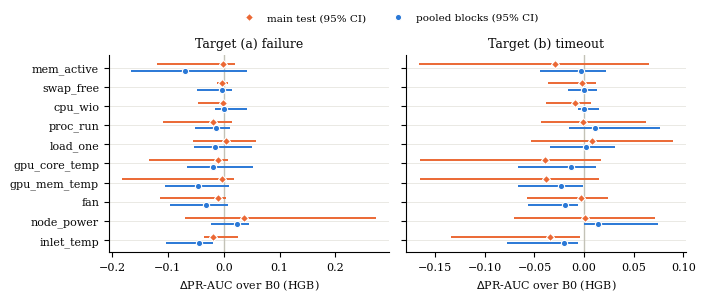

In [19]:
plt.rcParams.update({"font.family": "serif", "font.size": 8,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, INK, GRID, AXIS = "#2a78d6", "#eb6834", "#0b0b0b", "#e1e0d9", "#c3c2b7"
order = list(GROUPS)
fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.0), sharey=True)
y = np.arange(len(order))[::-1]
for ax, target in zip(axes, "ab"):
    t = final[final.target == target].set_index("group").loc[order]
    ax.axvline(0, color=AXIS, lw=1.0, zorder=1)
    for yy in y:
        ax.axhline(yy, color=GRID, lw=0.5, zorder=0)
    ax.hlines(y + 0.17, t.ci_main_low, t.ci_main_high, color=ORANGE, lw=1.4, zorder=2)
    ax.plot(t.delta_main, y + 0.17, "D", ms=4, color=ORANGE, mec="white", mew=0.8, zorder=3, label="main test (95% CI)")
    ax.hlines(y - 0.17, t.ci_pooled_low, t.ci_pooled_high, color=BLUE, lw=1.4, zorder=2)
    ax.plot(t.delta_pooled, y - 0.17, "o", ms=4.5, color=BLUE, mec="white", mew=0.8, zorder=3, label="pooled blocks (95% CI)")
    ax.set_title(f"Target {TARGET[target]}", fontsize=9, color=INK)
    ax.set_xlabel(r"$\Delta$PR-AUC over B0 (HGB)", color=INK)
axes[0].set_yticks(y)
axes[0].set_yticklabels(order, color=INK)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=7.5, bbox_to_anchor=(0.55, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.93))

## Pre-defined readings (Section V-E)

Fixed before any model was fitted (P11). The *top* is the up to three groups with the largest
positive main-test gains; it is *dominated* by a class if at least two of its groups belong to it.

1. top dominated by hardware-regulated metrics **and** W ≥ 0.7 — compatible with Ma et al.'s
   high SNR of such metrics;
2. top dominated by load metrics, **or** no group passes A — workload entanglement, critique of
   Skrzeczek's features;
3. some group relevant — incompatible with Ma et al. for job failure;
4. W < 0.7 **or** a block below the floor — fragile importance.

In [20]:
readings = {}
for target in "ab":
    t = final[final.target == target]
    top = t[t.delta_main > 0].sort_values("delta_main", ascending=False).group.head(3).tolist()
    Wt, below = W_primary[target]["W"], W_primary[target]["blocks_below_floor"]
    active = {1: len(top) >= 2 and sum(g in HARDWARE_REGULATED for g in top) >= 2 and Wt >= 0.7,
              2: (len(top) >= 2 and sum(g in LOAD_DRIVEN for g in top) >= 2) or not t.A.any(),
              3: (t.relevant == "yes").any(),
              4: Wt < 0.7 or bool(below)}
    readings[target] = [k for k, v in active.items() if v]
    print(f"target ({target}): top = {top}; readings activated: {readings[target]}")
assert readings == {"a": [2, 4], "b": [2, 4]}
top_a = final[(final.target == "a") & (final.delta_main > 0)].group.tolist()
assert sorted(top_a) == ["load_one", "node_power"]

target (a): top = ['node_power', 'load_one']; readings activated: [2, 4]
target (b): top = ['load_one', 'node_power']; readings activated: [2, 4]


### Skrzeczek's features

Each of Skrzeczek's five signals is mapped to the closest 2020 channel. A feature survives if its
group is relevant.

In [21]:
skrzeczek = pd.DataFrame([
    ("node_forks", "proc_run", "proxy (running processes, not the fork rate)"),
    ("disk_bytes_written", "swap_free", "proxy (memory/swap pressure)"),
    ("disk_bytes_written", "cpu_wio", "proxy (CPU waiting on I/O)"),
    ("gpu_temperature", "gpu_core_temp", "direct"),
    ("gpu_temperature", "gpu_mem_temp", "direct"),
    ("Tcp_InErrs", None, "absent: no TCP error metric in 2020"),
    ("memory_mapped", None, "absent: no equivalent channel"),
], columns=["skrzeczek_signal", "group", "mapping"])
rel = final.set_index(["group", "target"]).relevant
for t in "ab":
    skrzeczek[f"survives_{t}"] = [("not testable" if g is None else rel[(g, t)]) for g in skrzeczek.group]
print(skrzeczek.to_string(index=False))
kind = skrzeczek.groupby("skrzeczek_signal").mapping.first().str.split().str[0]
print(kind.value_counts().to_dict())
claim("Skrzeczek signals", kind.size, "5")
claim("Skrzeczek signals mapped directly", (kind == "direct").sum(), "1")
claim("Skrzeczek signals through proxies", (kind == "proxy").sum(), "2")
claim("Skrzeczek signals absent", (kind == "absent:").sum(), "2")
claim("Testable Skrzeczek features that survive", (skrzeczek[["survives_a", "survives_b"]] == "yes").sum().sum(), "0")

  skrzeczek_signal         group                                      mapping   survives_a   survives_b
        node_forks      proc_run proxy (running processes, not the fork rate)           no           no
disk_bytes_written     swap_free                 proxy (memory/swap pressure)           no           no
disk_bytes_written       cpu_wio                   proxy (CPU waiting on I/O)           no           no
   gpu_temperature gpu_core_temp                                       direct           no           no
   gpu_temperature  gpu_mem_temp                                       direct           no           no
        Tcp_InErrs          None          absent: no TCP error metric in 2020 not testable not testable
     memory_mapped          None                absent: no equivalent channel not testable not testable
{'absent:': 2, 'proxy': 2, 'direct': 1}
OK    Skrzeczek signals: 5   (paper: 5)
OK    Skrzeczek signals mapped directly: 1   (paper: 1)
OK    Skrzeczek signals through 

True

In [22]:
save_claims("08_results")

39 claims checked, 0 differ from the paper -> results/claims/08_results.csv


,claim,computed,paper,ok,note
0,"B0 PR-AUC, target (a), main test",0.250,0.250,True,
1,"B0 lift, target (a)",1.8,1.8,True,
2,"Prevalence, target (a), main test",13.7%,13.7%,True,
3,"B0 PR-AUC, target (b), main test",0.820,0.820,True,
4,"B0 lift, target (b)",8.7,8.7,True,
5,"Mean placebo gain, HGB, target (a), main test",-0.013,-0.013,True,paper: 'a placebo costs 0.013'
6,"Placebo importance threshold (p95), HGB, targe...",0.005,0.005,True,
7,Target (a): groups with a positive main-test gain,2,2,True,
8,"Target (a): node_power gain, main test",0.037,+0.037,True,
9,"Target (a): node_power main CI, low",-0.070,-0.070,True,
